# Cell cycle in the RNA and imaging of the same cells

Cytos measures RNA and imaging in the same cells, so we can ask at the single-cell level whether both modalities see the cell cycle, and how much it affects each of them. This notebook first scores the cell cycle from RNA and from DNA stain intensity, and then measures how much variance it explains and whether removing it helps knockouts separate from non-targeting cells.

The notebook uses [mantispy](https://github.com/scverse/mantispy) wherever a function exists, and scanpy for the RNA scores.

## Findings

RNA and imaging share a measurable cell cycle signal in single cells, but discrete phase calls are unreliable in this dataset, and a continuous position works better. All numbers come from the cells below, and the sections that follow show how we got each one.

**The RNA signal is real but noisy.** Each cell has only 5 S and 8 G2/M counts from the signature genes (medians). Even so, two random halves of the G2/M genes agree at r = 0.47 and the S genes at r = 0.26, against 0.01 and 0.06 for random genes of similar expression. Agreement rises with depth.

**A continuous position recovers the order of the cycle.** We built it from the cell cycle genes alone. Along it, the S score peaks first and the G2/M score follows. DNA content and nuclear area were not used to build the position, and they peak with G2/M. DNA content changes by 0.72 doublings between its lowest and highest bins, about 1.65-fold, which is below the 2-fold expected for G1 to G2.

**Imaging predicts the RNA scores on wells the model hasn't seen.** All usable features reach r = 0.57 for G2/M (0.71 after correcting for RNA noise) and r = 0.28 for S. The nucleus stain alone reaches 0.46 for G2/M, and cell shape with actin, membrane and mitochondria reaches 0.31 without any nucleus stain. These numbers show that the modalities agree, because the data has no independent cell cycle marker such as EdU or FUCCI.

**The discrete calls don't hold up.**

- `sc.tl.score_genes_cell_cycle` calls 12% of cells G1, which is too low for growing cells, and random genes also give a skewed split (70% G2/M), so the bins depend heavily on how the score is calibrated at this depth.
- `mt.tl.cell_cycle_phase` calls 73% of cells S. Log DNA intensity has one main peak with a shoulder, and two Gaussians fit barely better than one.
- The RNA and DNA calls agree poorly cell by cell.

**The cell cycle has a modest influence.** It explains less variance than RNA depth in RNA and imaging, and less than TNFα in protein. Knockouts and TNFα shift phase fractions by about 2% or less, and for CTNNB1 the RNA and DNA calls disagree on the direction. Regressing the scores out barely changes knockout separation, though noisy scores can only remove part of the effect.

**Other things we noticed.**

- RNA depth is close to cell size (rank correlation 0.94 with cell area), so a deep cell is mostly a large cell.
- DNA intensity rises with local cell density (0.37), which could be a staining or imaging effect and is a confounder for DNA-based calls.
- Cells flagged by `qc_area_outlier` are only mildly enriched for high G2/M scores (13.7% in the top decile, against 10% expected), so QC doesn't remove much of the cycle.
- Filtering genes before the PCA matters. Keeping genes detected in at least 1% of cells nearly doubles the energy distance for CTNNB1 (0.15 to 0.27) and TGFBR2 (0.13 to 0.25) in RNA.

## Limitations of the current mantispy tooling

- `tl.cell_cycle_phase` assumes two separated DNA peaks and gives no warning when the distribution has only one. Nothing reports the fit quality.
- It calls every uncertain cell S, so S mostly means "between the two fitted peaks".
- Its automatic feature search fails on names outside CellProfiler's `Nuclei_Intensity_IntegratedIntensity_DNA` pattern, so `dna_feature=` is needed here.
- It returns three bins, with no continuous position, no cycle score and no way to use RNA.
- It can't separate M from G2, or G0 from G1.
- Nothing in mantispy corrects a cycle regressor for noise, so `pp.regress_out` under-corrects when the regressor is unreliable.

In [1]:
from pathlib import Path

import anndata as ad
import mantispy as mt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA = Path("data")
URL = "https://exampledata.scverse.org/sbi2-cytodata/multiomics"
SHA256 = {
    "rna.h5ad": "a570888a00a0a98fd7b47ebace10f576fb04775b44732159ff419a81710bd293",
    "imaging.h5ad": "045854ba23a19bccb89615ab215ea9db92bd76050425ee3cdcbd31b115a652b4",
}
for name, sha in SHA256.items():
    pooch.retrieve(f"{URL}/{name}", known_hash=f"sha256:{sha}", fname=name, path=DATA)

## Load the same cells in both modalities

We keep the cells that pass QC and sample 5,000 of them per well. The RNA counts are loaded for exactly the sampled cells.

In [2]:
img = mt.io.read(DATA / "imaging.h5ad")
mt.pp.filter_cells(img)
img = mt.pp.downsample(img, n_per_group=5000, by="Metadata_Well")
img.obs["Metadata_Guide"] = img.obs["guide"].astype(str)
img.obs["Metadata_Condition"] = img.obs["condition"].astype(str)

rna_all = ad.read_h5ad(DATA / "rna.h5ad", backed="r")
rows = np.sort(rna_all.obs_names.get_indexer(img.obs_names))
rna = rna_all[rows].to_memory()
assert (rna.obs_names == img.obs_names).all()
rna.layers.clear()
rna.shape, img.shape

((60000, 54949), (60000, 1131))

## Cell cycle in the RNA

We score S and G2/M with the gene lists of Tirosh et al. 2016. Cells have about 1,450 RNA counts each, so a score could be mostly noise. To test this, we score each cell twice, from two random halves of a gene set, and correlate the two scores. We repeat the test with random genes of similar expression, which shows the correlation to expect without a shared program.

In [3]:
S_GENES = """MCM5 PCNA TYMS FEN1 MCM2 MCM4 RRM1 UNG GINS2 MCM6 CDCA7 DTL PRIM1 UHRF1 CENPU HELLS RFC2 RPA2 NASP
RAD51AP1 GMNN WDR76 SLBP CCNE2 UBR7 POLD3 MSH2 ATAD2 RAD51 RRM2 CDC45 CDC6 EXO1 TIPIN DSCC1 BLM CASP8AP2 USP1
CLSPN POLA1 CHAF1B BRIP1 E2F8""".split()
G2M_GENES = """HMGB2 CDK1 NUSAP1 UBE2C BIRC5 TPX2 TOP2A NDC80 CKS2 NUF2 CKS1B MKI67 TMPO CENPF TACC3 PIMREG SMC4 CCNB2
CKAP2L CKAP2 AURKB BUB1 KIF11 ANP32E TUBB4B GTSE1 KIF20B HJURP CDCA3 JPT1 CDC20 TTK CDC25C KIF2C RANGAP1 NCAPD2
DLGAP5 CDCA2 CDCA8 ECT2 KIF23 HMMR AURKA PSRC1 ANLN LBR CKAP5 CENPE CTCF NEK2 G2E3 GAS2L3 CBX5 CENPA""".split()
SETS = {"S": [g for g in S_GENES if g in rna.var_names], "G2M": [g for g in G2M_GENES if g in rna.var_names]}

detection = pd.DataFrame({
    name: {
        "genes found": f"{len(genes)} of {len(S_GENES if name == 'S' else G2M_GENES)}",
        "median counts per cell": np.median(np.asarray(rna[:, genes].X.sum(1)).ravel()),
        "median share of cells detecting a gene": np.median(np.asarray((rna[:, genes].X > 0).mean(0)).ravel()).round(3),
    }
    for name, genes in SETS.items()
})

detected = np.asarray((rna.X > 0).mean(0)).ravel()
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.tl.score_genes_cell_cycle(rna, s_genes=SETS["S"], g2m_genes=SETS["G2M"], random_state=0)
detection

,S,G2M
genes found,43 of 43,54 of 54
median counts per cell,5.0,8.0
median share of cells detecting a gene,0.067,0.082


In [4]:
def split_half(genes, seed):
    rng = np.random.default_rng(seed)
    shuffled = rng.permutation(genes)
    half = len(shuffled) // 2
    sc.tl.score_genes(rna, list(shuffled[:half]), score_name="_a", random_state=seed)
    sc.tl.score_genes(rna, list(shuffled[half:]), score_name="_b", random_state=seed)
    return np.corrcoef(rna.obs["_a"], rna.obs["_b"])[0, 1]


def matched_random(genes, seed):
    rng = np.random.default_rng(seed)
    mean = pd.Series(np.asarray(rna.X.mean(0)).ravel(), index=rna.var_names).drop(SETS["S"] + SETS["G2M"]).sort_values()
    where = np.clip(np.searchsorted(mean.values, rna[:, genes].X.mean(0).A1 if hasattr(rna[:, genes].X.mean(0), "A1") else np.asarray(rna[:, genes].X.mean(0)).ravel()) + rng.integers(-100, 100, len(genes)), 0, len(mean) - 1)
    return list(dict.fromkeys(mean.index[where]))


reliability = pd.DataFrame({
    name: {
        "gene set": np.mean([split_half(genes, s) for s in range(5)]),
        "matched random genes": np.mean([split_half(matched_random(genes, s), s) for s in range(5)]),
    }
    for name, genes in SETS.items()
}).round(3)
rna.obs = rna.obs.drop(columns=["_a", "_b"])
reliability.loc["estimated for the full gene set"] = (2 * reliability.loc["gene set"] / (1 + reliability.loc["gene set"])).round(3)
reliability

,S,G2M
gene set,0.262,0.467
matched random genes,0.055,0.010
estimated for the full gene set,0.415,0.637


The split-half correlation estimates the reliability of a half-length score, and the Spearman-Brown formula converts it to the full gene set. Next we ask how reliability depends on sequencing depth, and whether the discrete phase call means anything: if we run the same call on random genes of similar expression, a meaningful call should look clearly different.

In [5]:
tertile = pd.qcut(rna.obs["rna_total_counts"], 3, labels=["low depth", "mid depth", "high depth"])
by_depth = {}
for label in tertile.cat.categories:
    full = rna
    rna = full[(tertile == label).values].copy()
    by_depth[label] = {f"{name} split-half": np.mean([split_half(genes, s) for s in range(3)]) for name, genes in SETS.items()}
    by_depth[label]["median counts"] = rna.obs["rna_total_counts"].median()
    rna = full
display(pd.DataFrame(by_depth).round(3))

null_call = rna.copy()
sc.tl.score_genes_cell_cycle(null_call, s_genes=matched_random(SETS["S"], 0), g2m_genes=matched_random(SETS["G2M"], 1), random_state=0)
pd.DataFrame({
    "cell cycle genes": rna.obs["phase"].value_counts(normalize=True),
    "matched random genes": null_call.obs["phase"].value_counts(normalize=True),
}).round(3)

,low depth,mid depth,high depth
S split-half,0.205,0.240,0.341
G2M split-half,0.335,0.401,0.573
median counts,980.000,1476.000,2125.000


,cell cycle genes,matched random genes
phase,,
G2M,0.510,0.702
S,0.370,0.272
G1,0.119,0.026


In [6]:
obs = rna.obs
summary = {
    "phase fractions": obs["phase"].value_counts(normalize=True).round(3).to_dict(),
    "corr(S, G2M)": round(obs["S_score"].corr(obs["G2M_score"]), 3),
    "corr(S, log counts)": round(obs["S_score"].corr(np.log1p(obs["rna_total_counts"])), 3),
    "corr(G2M, log counts)": round(obs["G2M_score"].corr(np.log1p(obs["rna_total_counts"])), 3),
}
summary

{'phase fractions': {'G2M': 0.51, 'S': 0.37, 'G1': 0.119},
 'corr(S, G2M)': np.float64(0.098),
 'corr(S, log counts)': np.float64(0.143),
 'corr(G2M, log counts)': np.float64(0.243)}

## Cell cycle in the imaging

mantispy assigns a phase from integrated DNA intensity by fitting two Gaussians to the log intensity in each well. The stain is the Nucleus channel, and we use the raw values. Two separated peaks about a factor of two apart would mean the stain measures DNA content.

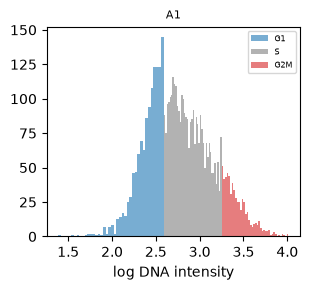

{'DNA quantiles (5, 25, 50, 75, 95%), relative to the well median': [0.55,
  0.78,
  1.0,
  1.3,
  1.92],
 'phase fractions from DNA': {'S': 0.729, 'G1': 0.154, 'G2M': 0.117}}

In [7]:
DNA = "Intensity_IntegratedIntensity_Nucleus"
mt.tl.cell_cycle_phase(img, dna_feature=DNA, by="Metadata_Well", layer="raw")
one_well = img[img.obs["Well"] == "A1"].copy()
mt.pl.cell_cycle(one_well, dna_feature=DNA, by="Well", layer="raw")
plt.show()

raw_dna = pd.Series(np.asarray(img[:, DNA].layers["raw"]).ravel(), index=img.obs_names)
dna = raw_dna / raw_dna.groupby(img.obs["Well"].astype(str).values).transform("median")
img.obs["dna_content"] = dna.values
{
    "DNA quantiles (5, 25, 50, 75, 95%), relative to the well median": dna.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(2).tolist(),
    "phase fractions from DNA": img.obs["Metadata_CellCyclePhase"].value_counts(normalize=True).round(3).to_dict(),
}

### Which DNA measurement works best?

The fit above needs a DNA measurement with two separated peaks. We compare candidates, including background-subtracted intensity, because a constant background compresses the G2/M to G1 ratio. For each one we report how much better two or three Gaussians fit than one (lower BIC is better), the distance between the two fitted peaks in doublings, and how it follows the RNA G2/M score. We also test whether mantispy finds a DNA feature by itself.

In [8]:
from sklearn.mixture import GaussianMixture

raw = pd.DataFrame(img.layers["raw"], index=img.obs_names, columns=img.var_names)
print("Integrated nucleus features:", [c for c in raw if "Integrated" in c and "Nucleus" in c and not c.startswith("Bkg")])
print("Base nucleus features:", [c for c in raw if c.startswith("Nucleus") or c.startswith("Bkg_Nucleus")])
print("Shape features:", list(raw.columns[img.var["modality"].astype(str) == "shape"][:6]))
try:
    trial = img.copy()
    mt.tl.cell_cycle_phase(trial, by="Metadata_Well", layer="raw", key_added="auto_phase")
    print("Auto-detect worked, phases:", trial.obs["auto_phase"].value_counts(normalize=True).round(3).to_dict())
except Exception as error:
    print("Auto-detect failed:", type(error).__name__, str(error)[:300])

area = raw["NuclearArea"].clip(lower=1)
candidates = {
    "integrated": raw[DNA],
    "nuclear mean x nuclear area": raw["Nucleus_Nuclear"] * area,
    "nuclear mean minus background x area": (raw["Nucleus_Nuclear"] - raw["Bkg_Nucleus_Nuclear"]) * area,
    "whole-cell mean minus background x cell area": (raw["Nucleus"] - raw["Bkg_Nucleus"]) * raw["Area"],
    "nuclear area": area,
}
rows = {}
well_labels = img.obs["Well"].astype(str).values
for name, values in candidates.items():
    positive = values.clip(lower=values[values > 0].quantile(0.001))
    log2 = np.log2(positive)
    centred = (log2 - log2.groupby(well_labels).transform("median")).to_numpy()[:, None]
    fits = {k: GaussianMixture(k, random_state=0).fit(centred) for k in (1, 2, 3)}
    peaks = np.sort(fits[2].means_.ravel())
    medians = pd.Series(centred.ravel()).groupby(rna_phase_early := obs["phase"].astype(str).values).median()
    rows[name] = {
        "BIC 2 vs 1 Gaussian, per cell": (fits[2].bic(centred) - fits[1].bic(centred)) / len(centred),
        "BIC 3 vs 2 Gaussians, per cell": (fits[3].bic(centred) - fits[2].bic(centred)) / len(centred),
        "distance between 2 peaks (doublings)": peaks[1] - peaks[0],
        "G2M vs G1 from RNA (doublings)": medians["G2M"] - medians["G1"],
        "Spearman with G2M score": stats.spearmanr(centred.ravel(), obs["G2M_score"])[0],
        "Spearman with S score": stats.spearmanr(centred.ravel(), obs["S_score"])[0],
    }
pd.DataFrame(rows).T.round(3)

Integrated nucleus features: ['Intensity_IntegratedIntensityEdge_Nucleus', 'Intensity_IntegratedIntensity_Nucleus']
Base nucleus features: ['Nucleus', 'Bkg_Nucleus', 'Nucleus_Nuclear', 'Bkg_Nucleus_Nuclear', 'Nucleus_Cytoplasmic', 'Bkg_Nucleus_Cytoplasmic', 'Nucleus_FractionAboveThreshold', 'Bkg_Nucleus_FractionAboveThreshold', 'Nucleus_MeanIntensityOfFractionAboveThreshold', 'Bkg_Nucleus_MeanIntensityOfFractionAboveThreshold', 'Nucleus_FractionAboveThreshold_Nuclear', 'Bkg_Nucleus_FractionAboveThreshold_Nuclear', 'Nucleus_FractionAboveThreshold_Cytoplasmic', 'Bkg_Nucleus_FractionAboveThreshold_Cytoplasmic', 'Nucleus_MeanIntensityOfFractionAboveThreshold_Nuclear', 'Bkg_Nucleus_MeanIntensityOfFractionAboveThreshold_Nuclear', 'Nucleus_MeanIntensityOfFractionAboveThreshold_Cytoplasmic', 'Bkg_Nucleus_MeanIntensityOfFractionAboveThreshold_Cytoplasmic', 'Nucleus_NuclearRatio', 'Bkg_Nucleus_NuclearRatio']
Shape features: ['Area', 'NuclearArea', 'AreaUm', 'NuclearAreaUm', 'AreaShape_Compactnes

Auto-detect failed: KeyError 'could not find an integrated DNA intensity feature; pass dna_feature= explicitly (the usual name is Nuclei_Intensity_IntegratedIntensity_DNA)'


,"BIC 2 vs 1 Gaussian, per cell","BIC 3 vs 2 Gaussians, per cell",distance between 2 peaks (doublings),G2M vs G1 from RNA (doublings),Spearman with G2M score,Spearman with S score
integrated,0.005,0.003,0.658,0.236,0.299,0.053
nuclear mean x nuclear area,-0.000,0.001,0.723,0.309,0.319,0.020
nuclear mean minus background x area,-0.000,0.002,0.726,0.310,0.319,0.020
whole-cell mean minus background x cell area,0.006,0.003,0.660,0.239,0.302,0.051
nuclear area,-0.001,-0.031,0.276,0.078,0.179,0.070


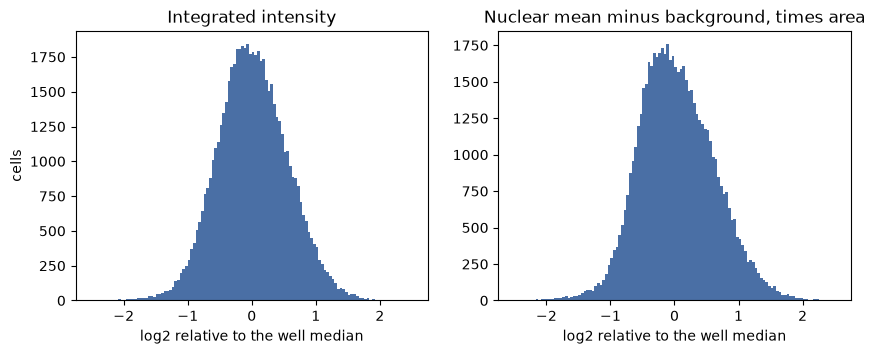

In [9]:
corrected = candidates["nuclear mean minus background x area"].clip(lower=1)
log_corrected = np.log2(corrected) - np.log2(corrected).groupby(well_labels).transform("median")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(np.log2(raw[DNA].clip(lower=1)) - np.log2(raw[DNA].clip(lower=1)).groupby(well_labels).transform("median"), bins=120, range=(-2.5, 2.5), color="#4a6fa5")
axes[0].set(title="Integrated intensity", xlabel="log2 relative to the well median", ylabel="cells")
axes[1].hist(log_corrected, bins=120, range=(-2.5, 2.5), color="#4a6fa5")
axes[1].set(title="Nuclear mean minus background, times area", xlabel="log2 relative to the well median")
plt.show()

## Do RNA and imaging agree in the same cell?

We compare the two phase calls cell by cell. We also ask whether DNA content rises from G1 through S to G2/M as called by RNA, where a stoichiometric stain would give a G2/M to G1 ratio near 2.

In [10]:
rna_phase, dna_phase = obs["phase"].astype(str).values, img.obs["Metadata_CellCyclePhase"].astype(str).values
agreement = pd.crosstab(pd.Series(rna_phase, name="RNA phase"), pd.Series(dna_phase, name="DNA phase"), normalize="index").round(3)
by_rna_phase = img.obs["dna_content"].groupby(rna_phase).median().round(3)
print("Median DNA content by RNA phase:", by_rna_phase.to_dict(), "G2M / G1:", round(by_rna_phase["G2M"] / by_rna_phase["G1"], 2))
print("Spearman with DNA content: S", round(stats.spearmanr(obs["S_score"], img.obs["dna_content"])[0], 3), "G2M", round(stats.spearmanr(obs["G2M_score"], img.obs["dna_content"])[0], 3))
agreement

Median DNA content by RNA phase: {'G1': 0.9129999876022339, 'G2M': 1.0750000476837158, 'S': 0.9470000267028809} G2M / G1: 1.18
Spearman with DNA content: S 0.053 G2M 0.299


DNA phase,G1,G2M,S
RNA phase,,,
G1,0.208,0.097,0.695
G2M,0.132,0.159,0.709
S,0.166,0.067,0.767


Next we predict the RNA scores from the imaging features, testing on wells the model hasn't seen. We use the features that mantispy selected, split by modality.

In [11]:
x = np.nan_to_num(np.clip(np.asarray(img.X), -10, 10))
selected, modality = img.var["selected"].values, img.var["modality"].astype(str).values
blocks = {
    "protein": x[:, selected & (modality == "protein")],
    "cell paint and shape": x[:, selected & np.isin(modality, ["cell_paint", "shape"])],
    "all selected": x[:, selected],
}
wells = img.obs["Well"].astype(str).values
prediction = {}
for name, block in blocks.items():
    prediction[name] = {}
    for target in ["S_score", "G2M_score"]:
        predicted = cross_val_predict(make_pipeline(StandardScaler(), Ridge(10)), block, obs[target], cv=GroupKFold(6), groups=wells)
        prediction[name][f"{target}: correlation on held-out wells"] = np.corrcoef(obs[target], predicted)[0, 1]
pd.DataFrame(prediction).round(3)

,protein,cell paint and shape,all selected
S_score: correlation on held-out wells,0.230,0.227,0.272
G2M_score: correlation on held-out wells,0.399,0.487,0.554


## How much variance does the cell cycle explain?

We use `mt.metrics.batch_variance_explained` to compute the variance-weighted R² of each modality's principal components on each covariate, which puts the cell cycle next to well, TNFα and knockout on one scale.

In [12]:
rna_hvg = sc.pp.highly_variable_genes(rna, n_top_genes=2000, inplace=False)["highly_variable"].values
cc_genes = rna.var_names.isin(SETS["S"] + SETS["G2M"])
shared = obs.assign(dna_phase=dna_phase, dna_content=img.obs["dna_content"].values, rna_phase=rna_phase, Well=wells)
shared["log_counts"] = np.log1p(shared["rna_total_counts"])
for column in img.obs.columns:
    if column.startswith("Metadata_") and column not in shared:
        shared[column] = img.obs[column].values


def space(values, n_pcs):
    a = ad.AnnData(X=np.asarray(values, dtype=np.float32), obs=shared.copy())
    a.obsm["X_pca"] = PCA(n_pcs, random_state=0).fit_transform(np.clip(StandardScaler().fit_transform(a.X), -10, 10))
    return a


# rare genes become outliers once scaled, so we keep genes detected in at least 1% of cells
common = detected >= 0.01
print(f"{common.sum()} genes detected in at least 1% of cells")
common_hvg = sc.pp.highly_variable_genes(rna[:, common], n_top_genes=2000, inplace=False)["highly_variable"].values
common_names = rna.var_names[common][common_hvg]
spaces = {
    "RNA, all HVGs (as in notebook 01)": space(rna[:, rna_hvg].X.toarray(), 30),
    "RNA": space(rna[:, common_names].X.toarray(), 30),
    "RNA without cell cycle genes": space(rna[:, common_names.difference(SETS["S"] + SETS["G2M"])].X.toarray(), 30),
    "protein": space(blocks["protein"], 10),
    "cell paint and shape": space(blocks["cell paint and shape"], 30),
}
KEYS = ["S_score", "G2M_score", "dna_content", "Well", "condition", "target_gene", "log_counts"]
pd.DataFrame({name: mt.metrics.batch_variance_explained(a, KEYS).set_index("key")["value"] for name, a in spaces.items()}).T.round(4)

9965 genes detected in at least 1% of cells


key,S_score,G2M_score,dna_content,Well,condition,target_gene,log_counts
"RNA, all HVGs (as in notebook 01)",0.0019,0.0199,0.0142,0.0310,0.0292,0.0072,0.0398
RNA,0.0096,0.0376,0.0408,0.0300,0.0262,0.0108,0.1080
RNA without cell cycle genes,0.0055,0.0203,0.0383,0.0306,0.0268,0.0113,0.1065
protein,0.0057,0.0080,0.0586,0.1118,0.1056,0.0058,0.0591
cell paint and shape,0.0047,0.0080,0.0689,0.0343,0.0084,0.0076,0.0989


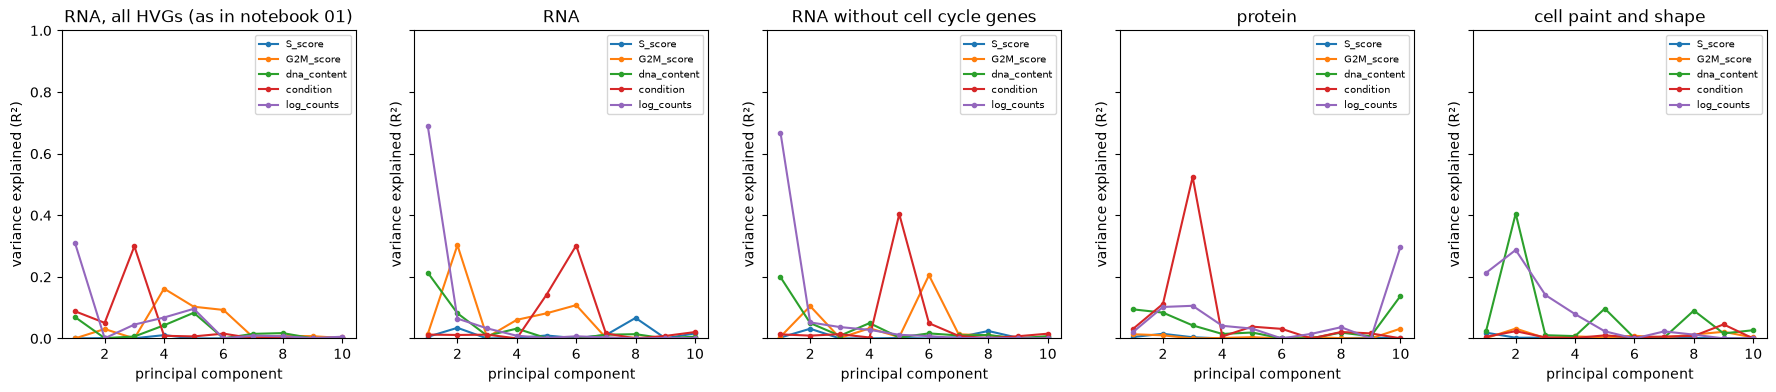

In [13]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=True)
for ax, (name, a) in zip(axes, spaces.items()):
    mt.pl.batch_variance(a, keys=["S_score", "G2M_score", "dna_content", "condition", "log_counts"], n_comps=10, ax=ax)
    ax.set_title(name)
plt.show()

## Do knockouts or TNFα change the cell cycle?

We compute the phase fractions per well and compare each knockout with the non-targeting cells of the same well, using a paired t-test over the 12 wells.

In [14]:
def phase_shift(phase):
    frac = pd.crosstab([shared["Well"], shared["target_gene"].astype(str)], phase, normalize="index")
    rows = []
    for ko in sorted(set(shared["target_gene"].astype(str)) - {"NTC"}):
        for ph in frac.columns:
            a, b = frac.xs(ko, level=1)[ph], frac.xs("NTC", level=1)[ph]
            rows.append({"knockout": ko, "phase": ph, "difference": (a - b).mean(), "p": stats.ttest_rel(a, b).pvalue})
    return pd.DataFrame(rows)


shift_rna, shift_dna = phase_shift(pd.Series(rna_phase, index=shared.index)), phase_shift(pd.Series(dna_phase, index=shared.index))
display(shift_rna.pivot(index="knockout", columns="phase", values="difference").round(3))
display(shift_dna.pivot(index="knockout", columns="phase", values="difference").round(3))
pd.concat({"RNA": shift_rna, "DNA": shift_dna}).sort_values("p").head(6).round(5)

phase,G1,G2M,S
knockout,,,
CTNNB1,0.021,-0.022,0.001
GSK3B,-0.006,-0.002,0.008
IL1R1,-0.001,0.005,-0.004
OR1I1,-0.008,0.010,-0.001
SMAD7,-0.011,0.006,0.005
TGFBR2,0.008,0.009,-0.017


phase,G1,G2M,S
knockout,,,
CTNNB1,-0.020,0.002,0.018
GSK3B,-0.007,0.004,0.003
IL1R1,0.014,0.002,-0.016
OR1I1,-0.000,0.004,-0.004
SMAD7,0.005,0.007,-0.012
TGFBR2,0.003,-0.002,-0.001


knockout phase  difference        p
RNA 0   CTNNB1    G1     0.02091  0.00100
DNA 0   CTNNB1    G1    -0.01988  0.01256
    8    IL1R1     S    -0.01628  0.02021
    2   CTNNB1     S     0.01765  0.02076
RNA 1   CTNNB1   G2M    -0.02153  0.02545
    9    OR1I1    G1    -0.00823  0.04293

In [15]:
well_condition = shared.groupby("Well", observed=True)["condition"].first().astype(str)
tnf = {}
for label, phase in {"RNA": rna_phase, "DNA": dna_phase}.items():
    frac = pd.crosstab(shared["Well"], pd.Series(phase, index=shared.index), normalize="index")
    for ph in frac.columns:
        a, b = frac.loc[well_condition == "TNFa", ph], frac.loc[well_condition == "baseline", ph]
        tnf[(label, ph)] = {"TNFa minus baseline": a.mean() - b.mean(), "p": stats.ttest_ind(a, b).pvalue}
pd.DataFrame(tnf).T.round(4)

TNFa minus baseline       p
RNA G1                0.0017  0.5994
    G2M               0.0005  0.9210
    S                -0.0022  0.6781
DNA G1               -0.0250  0.4162
    G2M              -0.0080  0.7171
    S                 0.0330  0.5043

## Does removing the cell cycle help knockouts separate?

We regress the RNA scores out of each modality with `mt.pp.regress_out`, fitting in each well on the non-targeting cells. We then compare two measures before and after: `mt.tl.edistance` compares single-cell distributions with the non-targeting cells, and `mt.tl.map` in activity mode compares profiles per guide and well.

In [16]:
def block_object(values):
    a = ad.AnnData(X=np.nan_to_num(np.asarray(values, dtype=np.float32)), obs=shared.copy())
    mt.io.stamp(a, resolution="object", feature_kind="embedding")
    mt.pp.annotate_controls(a, negcon=["NTC"])
    mt.pp.regress_out(a, keys=["S_score", "G2M_score"], by="Metadata_Well", reference="negcon", key_added="no_cycle")
    return a


objects = {
    "RNA, all HVGs (as in notebook 01)": block_object(spaces["RNA, all HVGs (as in notebook 01)"].obsm["X_pca"]),
    "RNA": block_object(spaces["RNA"].obsm["X_pca"]),
    "RNA without cell cycle genes": block_object(spaces["RNA without cell cycle genes"].obsm["X_pca"]),
    "protein": block_object(blocks["protein"]),
    "cell paint and shape": block_object(blocks["cell paint and shape"]),
}


def activity(a, layer):
    profiles = mt.tl.aggregate(a, by=("Metadata_Plate", "Metadata_Well", "Metadata_Guide"), layer=layer)
    mt.tl.map(profiles, mode="activity", batch="Metadata_Condition", null_size=1000)
    return profiles.uns["mantispy"]["map"].set_index("Metadata_Perturbation")["score"]


maps = {(name, label): activity(a, layer) for name, a in objects.items() for label, layer in {"before": None, "after": "no_cycle"}.items()}
pd.DataFrame(maps).T.round(3)

Metadata_Perturbation                     CTNNB1  GSK3B  IL1R1  OR1I1  SMAD7  \
RNA, all HVGs (as in notebook 01) before   0.767  0.603  0.508  0.642  0.515   
                                  after    0.765  0.593  0.507  0.638  0.511   
RNA                               before   0.787  0.592  0.525  0.627  0.537   
                                  after    0.788  0.588  0.521  0.618  0.538   
RNA without cell cycle genes      before   0.795  0.596  0.524  0.627  0.540   
                                  after    0.797  0.599  0.524  0.629  0.538   
protein                           before   0.666  0.591  0.504  0.626  0.507   
                                  after    0.671  0.587  0.504  0.622  0.506   
cell paint and shape              before   0.803  0.629  0.605  0.622  0.607   
                                  after    0.796  0.632  0.601  0.620  0.606   

Metadata_Perturbation                     TGFBR2  
RNA, all HVGs (as in notebook 01) before   0.662  
                                  after    0.668  
RNA                               before   0.773  
                                  after    0.781  
RNA without cell cycle genes      before   0.778  
                                  after    0.791  
protein                           before   0.520  
                                  after    0.525  
cell paint and shape              before   0.873  
                                  after    0.872

In [17]:
def energy(a, layer, condition):
    view = a[a.obs["Metadata_Condition"] == condition].copy()
    if layer:
        view.X = view.layers[layer]
    mt.tl.edistance(view, reference="negcon", n_permutations=200, max_reference=1000)
    return view.uns["mantispy"]["edistance"]


energies = {}
for name, a in objects.items():
    for label, layer in {"before": None, "after": "no_cycle"}.items():
        energies[(name, label)] = energy(a, layer, "baseline")
pd.DataFrame({k: v.set_index("group")["distance"] for k, v in energies.items()}).T.round(4)

group                                     CTNNB1   GSK3B   IL1R1     NTC  \
RNA, all HVGs (as in notebook 01) before  0.1456  0.0062  0.0023  0.0036   
                                  after   0.1473  0.0067  0.0025  0.0039   
RNA                               before  0.2656  0.0077  0.0067 -0.0023   
                                  after   0.2716  0.0084  0.0072 -0.0019   
RNA without cell cycle genes      before  0.2777  0.0080  0.0095 -0.0021   
                                  after   0.2817  0.0085  0.0106 -0.0018   
protein                           before  0.1727  0.0112  0.0019 -0.0042   
                                  after   0.1698  0.0124  0.0020 -0.0040   
cell paint and shape              before  0.1750  0.0234  0.0025 -0.0049   
                                  after   0.1724  0.0246  0.0029 -0.0042   

group                                      OR1I1   SMAD7  TGFBR2  
RNA, all HVGs (as in notebook 01) before  0.0027  0.0080  0.1287  
                                  after   0.0029  0.0087  0.1269  
RNA                               before  0.0006  0.0078  0.2542  
                                  after   0.0008  0.0083  0.2541  
RNA without cell cycle genes      before  0.0003  0.0115  0.2573  
                                  after   0.0004  0.0121  0.2543  
protein                           before  0.0060  0.0107  0.3473  
                                  after   0.0077  0.0131  0.3347  
cell paint and shape              before -0.0115  0.0070  0.5503  
                                  after  -0.0100  0.0089  0.5356

## A continuous position in the cycle

Three bins throw away the order of the cycle. Here we run a PCA on the cell cycle genes alone, averaged over each cell's nearest neighbours in that space because single cells are sparse, and take the angle in the first two components as a position. If this position is meaningful, DNA content and marker genes should rise and fall along it.

In [18]:
cycle_genes = [g for g in SETS["S"] + SETS["G2M"] if g in rna.var_names[common]]
cycle_x = StandardScaler().fit_transform(rna[:, cycle_genes].X.toarray()).clip(-10, 10)
cycle_pca = PCA(10, random_state=0).fit(cycle_x)
cycle_pcs = cycle_pca.transform(cycle_x)
print("Variance explained by the first 5 cell cycle PCs:", cycle_pca.explained_variance_ratio_[:5].round(3))
loadings = pd.DataFrame(cycle_pca.components_[:2].T, index=cycle_genes, columns=["PC1", "PC2"])
print("Top PC1:", loadings["PC1"].sort_values().index[-8:].tolist(), "bottom:", loadings["PC1"].sort_values().index[:4].tolist())
print("Top PC2:", loadings["PC2"].sort_values().index[-8:].tolist(), "bottom:", loadings["PC2"].sort_values().index[:8].tolist())
neighbors = sc.AnnData(obs=pd.DataFrame(index=rna.obs_names), obsm={"X_cycle": cycle_pcs[:, :5]})
sc.pp.neighbors(neighbors, use_rep="X_cycle", n_neighbors=30, transformer="sklearn")
weights = neighbors.obsp["connectivities"]
weights = weights.multiply(1 / np.maximum(np.asarray(weights.sum(1)), 1e-9)).tocsr()
smooth = np.asarray(weights @ cycle_pcs[:, :2])
smooth = smooth - smooth.mean(0)
angle = np.arctan2(smooth[:, 1], smooth[:, 0])
radius = np.hypot(smooth[:, 0], smooth[:, 1])
bins = pd.cut(angle, 12)
position = pd.DataFrame({
    "cells": pd.Series(radius).groupby(bins, observed=True).size(),
    "radius": pd.Series(radius).groupby(bins, observed=True).median(),
    "S score": obs["S_score"].reset_index(drop=True).groupby(bins, observed=True).median(),
    "G2M score": obs["G2M_score"].reset_index(drop=True).groupby(bins, observed=True).median(),
    "DNA (log2)": log_corrected.reset_index(drop=True).groupby(bins, observed=True).median(),
    "nuclear area": raw["NuclearArea"].reset_index(drop=True).groupby(bins, observed=True).median(),
})
position.round(3)

Variance explained by the first 5 cell cycle PCs: [0.037 0.019 0.012 0.011 0.011]
Top PC1: ['TPX2', 'ANLN', 'MKI67', 'AURKA', 'CDK1', 'AURKB', 'TUBB4B', 'TOP2A'] bottom: ['UNG', 'DTL', 'MCM6', 'WDR76']
Top PC2: ['MCM5', 'RRM2', 'UHRF1', 'UNG', 'MCM6', 'CDC6', 'PCNA', 'MCM4'] bottom: ['DLGAP5', 'NEK2', 'CENPF', 'CCNB2', 'AURKA', 'CENPE', 'TOP2A', 'TPX2']


,cells,radius,S score,G2M score,DNA (log2),nuclear area
"(-3.148, -2.618]",9237,2.077,-0.016,-0.032,-0.220,777.0
"(-2.618, -2.094]",6687,2.003,-0.071,0.026,-0.213,766.0
"(-2.094, -1.571]",2717,1.388,-0.045,0.116,-0.139,741.0
"(-1.571, -1.047]",2564,1.387,-0.034,0.173,0.008,778.5
"(-1.047, -0.524]",4162,1.972,-0.022,0.251,0.275,866.0
"(-0.524, -3.31e-05]",7085,2.889,0.042,0.330,0.502,970.0
"(-3.31e-05, 0.524]",4515,2.227,0.132,0.260,0.377,957.0
"(0.524, 1.047]",3588,1.811,0.190,0.180,0.164,915.0
"(1.047, 1.571]",4266,1.922,0.226,0.110,0.025,883.0
"(1.571, 2.094]",5066,1.876,0.210,0.042,-0.088,840.5


## Which imaging features follow the cycle?

We rank all usable features by their rank correlation with the RNA scores and with DNA content, within well. We then predict the G2/M score from feature families with the DNA stain removed, which shows whether a screen without a quantitative DNA stain could still recover the cycle.

In [19]:
usable = ~img.var_names.str.endswith("_NuclearRatio") & ~img.var["modality"].astype(str).isin(["background", "control"])
z = pd.DataFrame(x[:, usable], columns=img.var_names[usable], index=img.obs_names)
z = z - z.groupby(well_labels).transform("mean")
ranks = z.rank()
def spearman_all(target):
    t = pd.Series(np.asarray(target), index=z.index)
    t = (t - t.groupby(well_labels).transform("mean")).rank()
    return ranks.corrwith(t)
rho = pd.DataFrame({"G2M": spearman_all(obs["G2M_score"].values), "S": spearman_all(obs["S_score"].values), "DNA": spearman_all(log_corrected.values)})
rho["channel"] = img.var.loc[rho.index, "channel"].astype(str)
rho["modality"] = img.var.loc[rho.index, "modality"].astype(str)
print("Features with |rho| > 0.2 with the G2M score:", int((rho["G2M"].abs() > 0.2).sum()), "of", len(rho))
display(rho.reindex(rho["G2M"].abs().sort_values(ascending=False).index).head(15).round(3))
rho.groupby("channel")[["G2M", "S", "DNA"]].agg(lambda v: v.abs().median()).round(3)

Features with |rho| > 0.2 with the G2M score: 18 of 789


,G2M,S,DNA,channel,modality
Nucleus_FractionAboveThreshold_Nuclear,0.327,-0.023,0.407,Nucleus,cell_paint
Intensity_IntegratedIntensity_Nucleus,0.301,0.053,0.921,Nucleus,cell_paint
Intensity_IntegratedIntensity_Phospho-p38,0.285,0.003,0.545,Phospho-p38,protein
Nucleus_Nuclear,0.267,-0.028,0.749,Nucleus,cell_paint
Texture_SumVariance_3_03_256_Nucleus,0.263,-0.036,0.732,Nucleus,cell_paint
Texture_SumVariance_3_01_256_Nucleus,0.263,-0.036,0.732,Nucleus,cell_paint
Texture_SumVariance_3_02_256_Nucleus,0.261,-0.038,0.729,Nucleus,cell_paint
Texture_SumVariance_3_00_256_Nucleus,0.261,-0.038,0.729,Nucleus,cell_paint
Texture_Variance_3_01_256_Nucleus,0.260,-0.039,0.724,Nucleus,cell_paint
Texture_Variance_3_03_256_Nucleus,0.260,-0.039,0.724,Nucleus,cell_paint


,G2M,S,DNA
channel,,,
Actin,0.045,0.061,0.099
Cell-Membrane,0.027,0.066,0.332
ERK1_ERK2,0.075,0.031,0.227
Mitochondria,0.010,0.057,0.050
Nucleus,0.122,0.073,0.411
Phospho-ERK1_Phospho-ERK2,0.067,0.010,0.218
Phospho-HSP27,0.020,0.028,0.149
Phospho-p38,0.038,0.042,0.118


In [20]:
names = pd.Series(img.var_names)
family = {
    "shape only": (img.var["modality"].astype(str) == "shape").values,
    "actin, membrane, mitochondria": img.var["channel"].astype(str).isin(["Actin", "Cell-Membrane", "Mitochondria"]).values & usable,
    "shape, actin, membrane, mitochondria": (img.var["channel"].astype(str).isin(["Actin", "Cell-Membrane", "Mitochondria"]).values | (img.var["modality"].astype(str) == "shape").values) & usable,
    "nucleus stain only": (img.var["channel"].astype(str) == "Nucleus").values & usable,
    "nucleus stain texture only, no intensity": (img.var["channel"].astype(str) == "Nucleus").values & usable & names.str.startswith(("Texture", "RadialDistribution", "Granularity")).values,
    "protein only": (img.var["modality"].astype(str) == "protein").values & usable,
    "all usable": usable,
}
reliability_full = reliability.loc["estimated for the full gene set"]
result = {}
for name, mask in family.items():
    block = x[:, mask]
    row = {"features": int(mask.sum())}
    for target, short in {"G2M_score": "G2M", "S_score": "S"}.items():
        predicted = cross_val_predict(make_pipeline(StandardScaler(), Ridge(10)), block, obs[target], cv=GroupKFold(6), groups=well_labels)
        r = np.corrcoef(obs[target], predicted)[0, 1]
        row[f"{short}: r"] = r
        row[f"{short}: r corrected for RNA noise"] = r / np.sqrt(reliability_full[short])
    result[name] = row
pd.DataFrame(result).T.round(3)

,features,G2M: r,G2M: r corrected for RNA noise,S: r,S: r corrected for RNA noise
shape only,21.0,0.217,0.272,0.155,0.241
"actin, membrane, mitochondria",288.0,0.286,0.358,0.206,0.320
"shape, actin, membrane, mitochondria",309.0,0.307,0.384,0.217,0.337
nucleus stain only,96.0,0.462,0.579,0.183,0.283
"nucleus stain texture only, no intensity",72.0,0.394,0.494,0.175,0.272
protein only,384.0,0.409,0.512,0.233,0.361
all usable,789.0,0.567,0.710,0.276,0.429


## Does QC remove part of the cycle?

mantispy's outlier and area flags tend to catch small, round cells, and dividing cells look like that. So we score cells that failed each flag on the same scale and compare their G2/M scores with those of passing cells. Cells without a guide fail QC for an unrelated reason, so they serve as a comparison.

In [21]:
flags = ["qc_outlier", "qc_area_outlier", "qc_spatial_artifact", "qc_low_rna", "qc_guide_unassigned", "qc_no_nucleus"]
all_obs = rna_all.obs
rng = np.random.default_rng(0)
sampled = np.sort(np.concatenate([rng.choice(np.flatnonzero(all_obs[f].values), min(3000, int(all_obs[f].sum())), replace=False) for f in flags] + [rng.choice(np.flatnonzero(~all_obs["qc_fail"].values), 6000, replace=False)]))
sampled = np.unique(sampled)
qc_rna = rna_all[sampled].to_memory()
qc_rna.layers.clear()
sc.pp.normalize_total(qc_rna, target_sum=1e4)
sc.pp.log1p(qc_rna)
sc.tl.score_genes_cell_cycle(qc_rna, s_genes=SETS["S"], g2m_genes=SETS["G2M"], random_state=0)
qc_table = {}
for f in flags:
    m = qc_rna.obs[f].values.astype(bool) & (qc_rna.obs["rna_total_counts"].values >= 200)
    qc_table[f] = {"cells with at least 200 counts": int(m.sum()), "median G2M": qc_rna.obs.loc[m, "G2M_score"].median(), "median S": qc_rna.obs.loc[m, "S_score"].median(), "share in top 10% of G2M among passing": (qc_rna.obs.loc[m, "G2M_score"] > qc_rna.obs.loc[~qc_rna.obs["qc_fail"].values, "G2M_score"].quantile(0.9)).mean()}
passing = ~qc_rna.obs["qc_fail"].values
qc_table["passing QC"] = {"cells with at least 200 counts": int(passing.sum()), "median G2M": qc_rna.obs.loc[passing, "G2M_score"].median(), "median S": qc_rna.obs.loc[passing, "S_score"].median(), "share in top 10% of G2M among passing": 0.1}
pd.DataFrame(qc_table).T.round(3)

,cells with at least 200 counts,median G2M,median S,share in top 10% of G2M among passing
qc_outlier,2375.0,0.093,-0.008,0.087
qc_area_outlier,3196.0,-0.042,-0.067,0.137
qc_spatial_artifact,3805.0,0.062,0.015,0.082
qc_low_rna,0.0,NaN,NaN,NaN
qc_guide_unassigned,4538.0,0.047,0.012,0.069
qc_no_nucleus,566.0,0.044,0.008,0.060
passing QC,6000.0,0.072,0.035,0.100


## What else moves with the cycle?

Cell size, local density and RNA depth could all confound a cycle signal. We use `mt.tl.neighbors_local_density` for density, and compare rank correlations within well. Partial correlations show whether the link between RNA and DNA content survives controlling for size and depth.

In [22]:
import inspect
print(inspect.signature(mt.tl.neighbors_local_density))
density_key = None
try:
    dens = img.copy()
    dens.obs["Metadata_Center_X"] = dens.obs["X_tile"].values if "X_tile" in dens.obs else np.nan
    dens.obs["Metadata_Center_Y"] = dens.obs["Y_tile"].values if "Y_tile" in dens.obs else np.nan
    print("obs has tile coordinates:", "X_tile" in img.obs, "obsm:", list(img.obsm))
    if "spatial" in dens.obsm:
        coords = np.asarray(dens.obsm["spatial"])
        dens.obs["Metadata_Center_X"], dens.obs["Metadata_Center_Y"] = coords[:, 0], coords[:, 1]
    mt.tl.neighbors_local_density(dens)
    density_key = [c for c in dens.obs if "density" in c.lower()][0]
    density = dens.obs[density_key].values
    print("density column:", density_key)
except Exception as error:
    density = None
    print("Density failed:", type(error).__name__, str(error)[:400])

covariates = {"DNA": log_corrected.values, "cell area": raw["Area"].values, "nuclear area": raw["NuclearArea"].values, "log counts": np.log1p(obs["rna_total_counts"].values), "G2M": obs["G2M_score"].values, "S": obs["S_score"].values}
if density is not None:
    covariates["local density"] = density
frame = pd.DataFrame(covariates)
within = frame - frame.groupby(well_labels).transform("mean")
display(within.corr(method="spearman").round(3))
ranked = within.rank()
def partial(a, b, controls):
    d = np.column_stack([np.ones(len(ranked)), ranked[controls].to_numpy()])
    residual = lambda v: v - d @ np.linalg.lstsq(d, v, rcond=None)[0]
    return np.corrcoef(residual(ranked[a].to_numpy()), residual(ranked[b].to_numpy()))[0, 1]
{"G2M vs DNA": round(ranked["G2M"].corr(ranked["DNA"]), 3), "controlling for depth": round(partial("G2M", "DNA", ["log counts"]), 3), "controlling for depth and cell area": round(partial("G2M", "DNA", ["log counts", "cell area"]), 3), "controlling for depth, cell and nuclear area": round(partial("G2M", "DNA", ["log counts", "cell area", "nuclear area"]), 3)}

(adata: 'AnnData', k: 'int' = 15, by: 'str' = 'Metadata_ImageID', key_added: 'str' = 'Metadata_LocalDensity', copy: 'bool' = False) -> 'AnnData | None'


obs has tile coordinates: False obsm: ['spatial']


density column: Metadata_LocalDensity


,DNA,cell area,nuclear area,log counts,G2M,S,local density
DNA,1.000,0.445,0.505,0.409,0.319,0.020,0.368
cell area,0.445,1.000,0.589,0.941,0.177,0.137,0.241
nuclear area,0.505,0.589,1.000,0.603,0.179,0.070,0.066
log counts,0.409,0.941,0.603,1.000,0.227,0.149,0.177
G2M,0.319,0.177,0.179,0.227,1.000,0.134,0.011
S,0.020,0.137,0.070,0.149,0.134,1.000,0.018
local density,0.368,0.241,0.066,0.177,0.011,0.018,1.000


{'G2M vs DNA': np.float64(0.319),
 'controlling for depth': np.float64(0.255),
 'controlling for depth and cell area': np.float64(0.284),
 'controlling for depth, cell and nuclear area': np.float64(0.279)}